# Test 05 — 第二次预测

柱状图比较第一次和第二次预测后的速度分量。两次预测继续使用三分量速度；粒子 z 位置不随 z 速度移动。

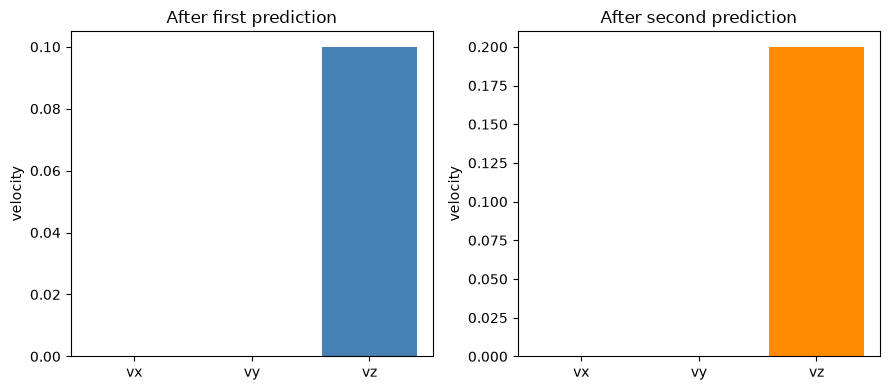

First vz = 0.1 | second vz = 0.2 | fixed z = 5.0


In [1]:
import os, sys
from pathlib import Path
module_dir = os.environ.get('BORIS_MODULE_DIR')
if module_dir is None:
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / 'build', parent / 'boris_cpp' / 'build'):
            if list(candidate.glob('boris_cpp*.so')): module_dir = str(candidate); break
        if module_dir: break
sys.path.insert(0, module_dir or '../build')
import matplotlib.pyplot as plt
import boris_cpp as boris
%matplotlib inline

grid = boris.PeriodicGrid(boris.Vec3(0,0,0), boris.Vec3(4,4,0), (4,4,1))
data = boris.PredictionInput()
data.electric = [boris.Vec3(0,0,1) for _ in range(grid.size())]
data.magnetic = [boris.Vec3(0,0,0) for _ in range(grid.size())]
data.particles = [boris.Particle(boris.Vec3(1,1,5), boris.Vec3(0,0,0), 1, 1)]
first = boris.predict_first(grid, data, 0.1)
second = boris.predict_second(grid, data, first, 0.1)
p1, p2 = first.particles_next[0], second.particles_next[0]
assert abs(p1.velocity.z - 0.1) < 1e-12
assert abs(p2.velocity.z - 0.2) < 1e-12
assert p1.position.z == p2.position.z == 5

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
labels = ['vx','vy','vz']
axes[0].bar(labels, [p1.velocity.x,p1.velocity.y,p1.velocity.z], color='steelblue')
axes[0].set(title='After first prediction', ylabel='velocity')
axes[1].bar(labels, [p2.velocity.x,p2.velocity.y,p2.velocity.z], color='darkorange')
axes[1].set(title='After second prediction', ylabel='velocity')
plt.tight_layout(); plt.show()
print('First vz =', p1.velocity.z, '| second vz =', p2.velocity.z, '| fixed z =', p2.position.z)